# Labastida PT-F2: Chunk size and overlap experiment

**ITC-C508 Lab Exercise PT-F2 (Part 2).** A controlled experiment comparing 12 chunk size / overlap configurations on the PDF from Part 1, scored with Precision@3, Recall@3 and MRR@3, with efficiency measurements and an Excel log containing Tables A, B and C.

This notebook is standalone; `Labastida_PT_F1_SEALION_GPU.ipynb` is unchanged. It reuses PT-F1's exact PDF extraction and `create_chunks` code, the same embedding model (`all-MiniLM-L6-v2` on CPU), the same FAISS index type and k = 3, so the only thing that varies is chunk size and overlap.

**Retrieval only, no GPU required.** Precision@3, Recall@3 and MRR@3 measure retrieval, so SEA-LION is not loaded; the language model and prompt from Part 1 are held constant by not changing them. A CPU runtime is enough.

**Run order:** Setup 1 → Setup 2 → Steps 1–4 (PDF, text, baseline chunks, embedder) → Step 5 (configurations) → **Step 6: fill in your test questions** → Steps 7–11. In Colab, leave `PDF_PATH` empty to get an upload picker; elsewhere set `PDF_PATH` to your PDF.

## Setup 1: Install packages

Run once per fresh runtime. Restart the kernel if the installer asks.

In [1]:
%pip install -q "sentence-transformers>=3,<6" faiss-cpu pypdf pandas openpyxl matplotlib


## Setup 2: Imports

In [2]:
import re
import json
import time
import shutil
import itertools
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import faiss
import matplotlib.pyplot as plt
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer
from IPython.display import display, FileLink
from openpyxl.styles import Font, PatternFill, Alignment

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    colab_files = None
    IN_COLAB = False

print("Environment:", "Google Colab" if IN_COLAB else "Jupyter / other")


Environment: Google Colab


## Step 1: Configuration

`CHUNK_SIZE` / `CHUNK_OVERLAP` / `TOP_K` are the **Part 1 baseline** and should stay at 1000 / 200 / 3. The 12 experimental configurations are defined in Step 5. `LLM_NAME` is recorded in the settings sheet only; it is not loaded.

In [3]:
PDF_PATH = ""  # Example: "documents/your_document.pdf"; leave empty in Colab for an upload picker
OUTPUT_DIR = Path("pt_f2_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Part 1 baseline (kept constant for reference)
CHUNK_SIZE = 1000
CHUNK_OVERLAP = 200
TOP_K = 3
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDING_DEVICE = "cpu"
LLM_NAME = "aisingapore/Llama-SEA-LION-v3-8B-IT"  # held constant from Part 1; not used for retrieval metrics

if CHUNK_SIZE <= 0 or not 0 <= CHUNK_OVERLAP < CHUNK_SIZE:
    raise ValueError("Require CHUNK_SIZE > 0 and 0 <= CHUNK_OVERLAP < CHUNK_SIZE.")


## Step 2: Select the same PDF used in Part 1

In Colab, select exactly one PDF when prompted. Elsewhere, set `PDF_PATH` in Step 1.

In [4]:
if PDF_PATH.strip():
    pdf_path = Path(PDF_PATH).expanduser()
elif IN_COLAB:
    uploaded = colab_files.upload()
    if len(uploaded) != 1:
        raise ValueError("Upload exactly one PDF, then rerun this cell.")
    pdf_path = Path(next(iter(uploaded)))
    del uploaded  # Release uploaded bytes from host memory.
else:
    raise ValueError("Set PDF_PATH in Step I-1 to the PDF uploaded through your file browser.")

if not pdf_path.is_file() or pdf_path.suffix.lower() != ".pdf":
    raise ValueError(f"Expected an existing PDF file, got: {pdf_path}")
pdf_file = str(pdf_path)
print("Selected PDF:", pdf_file)


Saving dmw_source_b_guidance.pdf to dmw_source_b_guidance.pdf
Selected PDF: dmw_source_b_guidance.pdf


## Step 3: Extract PDF text

Identical to PT-F1 Step I-3: each page is extracted and whitespace-normalized separately; empty pages are skipped.

In [5]:
# ============================================================
# 6. EXTRACT TEXT FROM PDF
# ============================================================

print("\n")
print("=" * 70)
print("EXTRACTING PDF TEXT")
print("=" * 70)

reader = PdfReader(pdf_file)

pages = []

for page_number, page in enumerate(reader.pages, start=1):

    page_text = page.extract_text()

    if page_text:

        # Normalize whitespace
        page_text = re.sub(
            r"\s+",
            " ",
            page_text
        ).strip()

        if page_text:
            pages.append({
                "page": page_number,
                "text": page_text
            })


print("PDF pages:", len(reader.pages))
print("Pages containing text:", len(pages))
# ============================================================
# 7. CHECK WHETHER TEXT WAS EXTRACTED
# ============================================================

if len(pages) == 0:
    raise RuntimeError(
        "No text could be extracted from the PDF. "
        "The PDF may consist of scanned images and require OCR."
    )




EXTRACTING PDF TEXT
PDF pages: 12
Pages containing text: 12


## Step 4: Chunking function, baseline chunks and embedding model

`create_chunks` is copied unchanged from PT-F1 Step I-4 (page-by-page character windows), so every configuration is chunked exactly as in Part 1. The baseline chunks are built here so Step 7 can confirm the experiment reproduces Part 1 for 1000 / 200. The embedding model is loaded once and reused for every configuration.

In [6]:
# ============================================================
# 8. CREATE DOCUMENT CHUNKS
# ============================================================

def create_chunks(
    pages,
    chunk_size,
    chunk_overlap
):
    """
    Split each page into character-based chunks.

    Chunking is performed independently for each page.
    Overlap is maintained between consecutive chunks
    from the same page.
    """

    chunks = []
    chunk_id = 0

    step_size = chunk_size - chunk_overlap

    for page_data in pages:

        page_number = page_data["page"]
        page_text = page_data["text"]

        start = 0

        while start < len(page_text):

            end = start + chunk_size

            chunk_text = page_text[start:end].strip()

            if chunk_text:
                chunks.append({
                    "chunk_id": chunk_id,
                    "page": page_number,
                    "text": chunk_text
                })

                chunk_id += 1

            # Move forward while maintaining overlap
            start += step_size

    return chunks


# Baseline (Part 1) chunks, used as a reproducibility check in Step 7.
chunks = create_chunks(pages, CHUNK_SIZE, CHUNK_OVERLAP)
if not chunks:
    raise RuntimeError("No chunks were generated. Check the extracted PDF text.")
print(f"Baseline {CHUNK_SIZE}/{CHUNK_OVERLAP}: {len(chunks)} chunks")

embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME, device=EMBEDDING_DEVICE)
print("Embedding model:", EMBEDDING_MODEL_NAME,
      "| max input tokens:", embedding_model.max_seq_length)


Baseline 1000/200: 50 chunks


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model: sentence-transformers/all-MiniLM-L6-v2 | max input tokens: 256


## Step 5: Define the 12 chunking configurations

Generated with a nested loop over chunk sizes and overlap ratios (0 %, 10 %, 20 %). This reproduces the required C1–C5 exactly and makes **C12 (1000 / 200) the Part 1 baseline**. Using the same overlap percentages at every size lets you compare chunk sizes at equal overlap (Step 7 question 5). You may edit `CHUNK_SIZES` or `OVERLAP_RATIOS`; keep 1000 / 20 % so the baseline stays in the comparison.

In [7]:
EXP_DIR = OUTPUT_DIR / "pt_f2_experiment"
EXP_DIR.mkdir(parents=True, exist_ok=True)

EXP_TOP_K = 3
BASELINE_SIZE, BASELINE_OVERLAP = 1000, 200

CHUNK_SIZES = [300, 500, 750, 1000]
OVERLAP_RATIOS = [0.0, 0.10, 0.20]

EXPERIMENT_CONFIGS = []
for size in CHUNK_SIZES:
    for ratio in OVERLAP_RATIOS:
        overlap = int(round(size * ratio))
        EXPERIMENT_CONFIGS.append({
            "config": f"C{len(EXPERIMENT_CONFIGS) + 1}",
            "chunk_size": size,
            "overlap": overlap,
            "overlap_pct": int(round(ratio * 100)),
            "is_baseline": (size, overlap) == (BASELINE_SIZE, BASELINE_OVERLAP),
        })

# Implementation checks: valid settings, no duplicates, exactly one baseline.
for cfg in EXPERIMENT_CONFIGS:
    if cfg["chunk_size"] <= 0 or not 0 <= cfg["overlap"] < cfg["chunk_size"]:
        raise ValueError(f"{cfg['config']}: overlap must be >= 0 and smaller than chunk size.")
if len({(c["chunk_size"], c["overlap"]) for c in EXPERIMENT_CONFIGS}) != len(EXPERIMENT_CONFIGS):
    raise ValueError("Duplicate chunk size / overlap combinations.")
if sum(c["is_baseline"] for c in EXPERIMENT_CONFIGS) != 1:
    raise ValueError("Include the 1000 / 200 baseline exactly once.")
if TOP_K != EXP_TOP_K:
    print(f"Note: Step I-1 TOP_K is {TOP_K}; the experiment always uses k = {EXP_TOP_K}.")

page_lengths = [len(p["text"]) for p in pages]
print(f"Pages with text: {len(pages)} | page length chars: "
      f"min {min(page_lengths)}, median {int(np.median(page_lengths))}, max {max(page_lengths)}")
print(pd.DataFrame(EXPERIMENT_CONFIGS).to_string(index=False))
for cfg in EXPERIMENT_CONFIGS:
    if cfg["chunk_size"] >= max(page_lengths):
        print(f"Warning: {cfg['config']} chunk size >= longest page; chunking is per page, "
              "so every page becomes one chunk and larger sizes will give identical results.")


Pages with text: 12 | page length chars: min 909, median 3152, max 3843
config  chunk_size  overlap  overlap_pct  is_baseline
    C1         300        0            0        False
    C2         300       30           10        False
    C3         300       60           20        False
    C4         500        0            0        False
    C5         500       50           10        False
    C6         500      100           20        False
    C7         750        0            0        False
    C8         750       75           10        False
    C9         750      150           20        False
   C10        1000        0            0        False
   C11        1000      100           10        False
   C12        1000      200           20         True


## Step 6: Test questions and evidence units (ground truth)

Copy your verified Part 1 questions into `TEST_QUESTIONS`: at least **3 Easy, 3 Average and 3 Difficult**. For each question, list its **evidence units**, the separate facts needed to answer it. A Difficult question that needs facts from two sections gets two units.

Each unit has:
- `page`: the PDF page number of the fact (an int, a list of ints, or `None` for any page).
- `must_contain`: one or more **short exact phrases** copied from the PDF that together establish the fact (for example the person's name *and* the position title). All phrases of one unit must be on the same page.

Run the helper cell first and use `find_in_pdf("phrase")` to confirm wording and page numbers.

**Relevance rule (identical for every configuration):** a retrieved chunk covers a unit only if it is on the unit's page and contains *all* of the unit's phrases. A chunk is relevant if it covers at least one unit of the question. Requiring the answer and its qualifier together keeps "merely mentions the same keyword" from counting as relevant. Matching ignores case, extra spaces and curly vs straight quotes.

If you inspect the log and disagree with an automatic judgment, record it in `RELEVANCE_OVERRIDES` (keyed by configuration, question ID and the chunk ID shown in Table C) with a note; overrides are labelled in the log.

In [8]:
_PUNCT_MAP = str.maketrans({"\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"',
                            "\u2013": "-", "\u2014": "-", "\u00a0": " "})


def normalize_for_match(text):
    text = unicodedata.normalize("NFKC", str(text)).translate(_PUNCT_MAP)
    return re.sub(r"\s+", " ", text).strip().lower()


def find_in_pdf(phrase, context=120, max_hits=10):
    """Print the pages and surrounding text where `phrase` occurs (normalized view)."""
    target = normalize_for_match(phrase)
    hits = 0
    for page_data in pages:
        norm = normalize_for_match(page_data["text"])
        start = norm.find(target)
        while start != -1 and hits < max_hits:
            left, right = max(0, start - context), start + len(target) + context
            print(f"Page {page_data['page']}: ...{norm[left:right]}...\n")
            hits += 1
            start = norm.find(target, start + 1)
    if hits == 0:
        print("Not found. Check spelling, or copy the wording from the chunk inspection workbook.")

# Example usage (uncomment):
# find_in_pdf("Regional Director")


In [20]:
# Step 6: replace the whole TEST_QUESTIONS cell with this.
# Source: dmw_source_b_test_questions.md (PT-F1 Step 2, prepared 23 Oct 2026)
# Dataset: dmw_source_b_guidance.pdf (12 pages)
# One evidence unit = one "Relevant passage ref"; unit ID = question ID + passage ref.
# must_contain = that passage's check phrase; page = the page in the passage ref.

TEST_QUESTIONS = [
    # ---------- EASY: single explicit fact in one passage ----------
    {"qid": "Q01", "difficulty": "Easy",
     "question": "According to the POEA warning about illegal recruitment on online dating sites, "
                 "the job offers were for work in which countries?",
     "expected_answer": "The United States and Canada.",
     "evidence": [
         {"unit_id": "Q01:p8-s14-par1", "page": 8,
          "must_contain": ["bound to the United States and Canada"]},
     ]},
    {"qid": "Q02", "difficulty": "Easy",
     "question": "How many modules does the PEOS online seminar have?",
     "expected_answer": "Eight (8) modules.",
     "evidence": [
         {"unit_id": "Q02:p12-s25", "page": 12,
          "must_contain": ["eight (8) modules"]},
     ]},
    {"qid": "Q03", "difficulty": "Easy",
     "question": "In the illegal recruitment scheme called the “Backdoor Points Scheme,” "
                 "how are workers sent abroad?",
     "expected_answer": "Not through regular exit channels like airports; usually deployed through cargo ships.",
     "evidence": [
         {"unit_id": "Q03:p4-s5-item6", "page": 4,
          "must_contain": ["deployed usually through cargo ships"]},
     ]},
    {"qid": "Q04", "difficulty": "Easy",
     "question": "Ayon sa POEA, saan karaniwang nakikipag-transaksiyon ang illegal recruiter sa mga aplikante?",
     "expected_answer": "Sa mga pampublikong lugar tulad ng restaurant, mall, atbpa., "
                        "at hindi sa opisina ng lisensyadong ahensiya.",
     "evidence": [
         {"unit_id": "Q04:p2-s3-sign4", "page": 2,
          "must_contain": ["sa mga pampublikong lugar tulad ng restaurant, mall"]},
     ]},

    # ---------- AVERAGE: interpretation or closely related facts ----------
    {"qid": "Q05", "difficulty": "Average",
     "question": "When is illegal recruitment considered an offense involving economic sabotage?",
     "expected_answer": "When committed by a syndicate (3 or more persons conspiring) or in large scale "
                        "(against 3 or more persons, individually or as a group).",
     "evidence": [
         {"unit_id": "Q05:p2-s2-par3", "page": 2,
          "must_contain": ["considered as offense involving economic sabotage"]},
     ]},
    {"qid": "Q06", "difficulty": "Average",
     "question": "What conditions should be met before a jobseeker pays a placement fee?",
     "expected_answer": "A valid employment contract and an official receipt; the fee should not exceed "
                        "one month salary, exclusive of documentation and processing costs.",
     "evidence": [
         {"unit_id": "Q06:p3-s4-tip6", "page": 3,
          "must_contain": ["unless you have a valid employment contract and an official receipt"]},
         {"unit_id": "Q06:p3-s4-tip5", "page": 3,
          "must_contain": ["equivalent to one month salary"]},
     ]},
    {"qid": "Q07", "difficulty": "Average",
     "question": "Can visa consultants or language training centers recruit Filipino workers for jobs abroad?",
     "expected_answer": "Visa consultants only with a POEA license; language training centers are not "
                        "allowed to recruit at all.",
     "evidence": [
         {"unit_id": "Q07:p5-s8-par1", "page": 5,
          "must_contain": ["without the necessary license or authority from the POEA constitutes illegal recruitment"]},
         {"unit_id": "Q07:p5-s8-par2", "page": 5,
          "must_contain": ["language training centers are not allowed to engage in the recruitment and placement"]},
     ]},
    {"qid": "Q08", "difficulty": "Average",
     "question": "What is a No Objection Certification (NOC) for Special Recruitment Authority, "
                 "and who may avail of it?",
     "expected_answer": "A DMW clearance allowing a licensed agency to recruit outside its registered "
                        "business address for Special Recruitment Activities; available to licensed "
                        "recruitment agencies.",
     "evidence": [
         {"unit_id": "Q08:p11-s22", "page": 11,
          "must_contain": ["conducting recruitment activities outside its registered business address"]},
     ]},

    # ---------- DIFFICULT: multiple passages / cross-section / disambiguation ----------
    {"qid": "Q09", "difficulty": "Difficult",
     "question": "POEA Advisory No. 83 (2020) and Advisory No. 32 (2021) both warn about scammers who "
                 "ask jobseekers for money. How much did each scam ask for, and what was the payment "
                 "supposedly for?",
     "expected_answer": "No. 83: P3,000 to P3,800 reservation fee for online interviews, seminar or "
                        "screening; No. 32: P3,000 to P5,000 for document processing and slots for "
                        "online orientation or free training.",
     "evidence": [
         {"unit_id": "Q09:p5-s9-par1", "page": 5,
          "must_contain": ["from P3,000 to P3,800 as reservation fee for online interviews, seminar, or screening"]},
         {"unit_id": "Q09:p7-s13-par3", "page": 7,
          "must_contain": ["ranging from P3,000 to P5,000"]},
     ]},
    {"qid": "Q10", "difficulty": "Difficult",
     "question": "Can a travel agency that shows a valid DTI certificate of registration legally recruit "
                 "workers for jobs abroad? Support the answer with the guidance.",
     "expected_answer": "No. A DTI registration, even if valid, does not authorize recruitment because "
                        "travel agencies are not licensed by the POEA; do not deal with travel agencies "
                        "that promise overseas employment.",
     "evidence": [
         {"unit_id": "Q10:p6-s11-par2", "page": 6,
          "must_contain": ["which even if valid, does not authorize them to conduct recruitment activities"]},
         {"unit_id": "Q10:p3-s4-tip8", "page": 3,
          "must_contain": ["Do not deal with training centers and travel agencies"]},
     ]},
    {"qid": "Q11", "difficulty": "Difficult",
     "question": "A recruiter offers to send a jobseeker abroad on a tourist visa. What scheme is this, "
                 "and which warnings in the guidance cover it?",
     "expected_answer": "The Tourist-Worker Scheme; covered by tip 9 (Do not accept a tourist visa) and "
                        "Filipino warning sign 8 (gamit ang tourist o visit visa).",
     "evidence": [
         {"unit_id": "Q11:p3-s5-item2", "page": 3,
          "must_contain": ["purportedly as tourist"]},
         {"unit_id": "Q11:p3-s4-tip9", "page": 3,
          "must_contain": ["Do not accept a tourist visa."]},
         {"unit_id": "Q11:p3-s3-sign8", "page": 3,
          "must_contain": ["gamit ang tourist o visit visa"]},
     ]},
    {"qid": "Q12", "difficulty": "Difficult",
     "question": "A worker wants to file a complaint against (a) a licensed recruitment agency and "
                 "(b) an illegal recruiter. Which DMW Citizen's Charter services cover each case, and "
                 "where is a criminal case for illegal recruitment filed?",
     "expected_answer": "(a) RV Case; (b) Illegal Recruitment and/or TIP Case, filed with the Regional "
                        "Trial Court; Provision of Legal Assistance covers both; all free.",
     "evidence": [
         {"unit_id": "Q12:p11-s21", "page": 11,
          "must_contain": ["file an administrative complaint against a licensed Philippine recruitment agency"]},
         {"unit_id": "Q12:p10-s20", "page": 10,
          "must_contain": ["filed with the Regional Trial Court (RTC)"]},
         {"unit_id": "Q12:p10-s18", "page": 10,
          "must_contain": ["4. Illegal Recruiters and Human Traffickers"]},
     ]},
]

# Manual relevance judgments, applied after the automatic exact-phrase rule.
# Key: (config, qid, chunk_id as shown in Table C).
# Basis: the handout counts a chunk as relevant when it "contains evidence that supports
# answering the question". An audit of every "No" in the first run found exactly 5 chunks
# whose check phrase was cut by a chunk boundary while the answer-bearing words remain.
# All other "No" judgments were genuine misses and are left unchanged.
RELEVANCE_OVERRIDES = {
    ("C1", "Q04", 20): {"relevant": True, "covers": ["Q04:p2-s3-sign4"],
                        "note": "Check phrase cut at chunk end; answer 'sa mga pampublikong lugar' present"},
    ("C4", "Q04", 12): {"relevant": True, "covers": ["Q04:p2-s3-sign4"],
                        "note": "Check phrase cut at chunk end; answer 'sa mga pampublikong lugar' present"},
    ("C7", "Q04", 8): {"relevant": True, "covers": ["Q04:p2-s3-sign4"],
                       "note": "Check phrase cut at chunk end; answer 'sa mga pampublikong lugar' present"},
    ("C10", "Q04", 6): {"relevant": True, "covers": ["Q04:p2-s3-sign4"],
                        "note": "Check phrase cut at chunk end; answer 'sa mga pampublikong lugar' present"},
    ("C1", "Q10", 65): {"relevant": True, "covers": ["Q10:p6-s11-par2"],
                        "note": "Check phrase cut at both ends; 'does not authorize them to conduct recruitment' present"},
}

## Step 7: Validate the ground truth

Stops with a clear message if a question is blank, a difficulty level has fewer than 3 questions, or an evidence phrase is not on its page. `Min_Span_Chars` is the shortest stretch of page text containing all of a unit's phrases: a unit whose span exceeds a chunk size cannot fit in one chunk of that size. That is a real fragmentation effect worth citing in your discussion, not an error.

In [21]:
DIFFICULTY_ORDER = ["Easy", "Average", "Difficult"]
page_text_by_number = {p["page"]: p["text"] for p in pages}
norm_page_text = {n: normalize_for_match(t) for n, t in page_text_by_number.items()}


def unit_page_list(unit):
    page = unit.get("page")
    if page is None:
        return list(norm_page_text)
    return [page] if isinstance(page, int) else list(page)


def min_span_chars(norm_text, norm_snippets, cap=20):
    occurrences = []
    for snippet in norm_snippets:
        positions = [m.start() for m in re.finditer(re.escape(snippet), norm_text)][:cap]
        if not positions:
            return None
        occurrences.append([(pos, pos + len(snippet)) for pos in positions])
    return min(max(end for _, end in combo) - min(start for start, _ in combo)
               for combo in itertools.product(*occurrences))


problems, GROUND_TRUTH, gt_rows = [], [], []
seen_qids, seen_units = set(), set()
for q in TEST_QUESTIONS:
    qid = q.get("qid", "?")
    if qid in seen_qids:
        problems.append(f"{qid}: duplicate question ID")
    seen_qids.add(qid)
    if q.get("difficulty") not in DIFFICULTY_ORDER:
        problems.append(f"{qid}: difficulty must be one of {DIFFICULTY_ORDER}")
    if not str(q.get("question", "")).strip():
        problems.append(f"{qid}: question is empty")
    if not q.get("evidence"):
        problems.append(f"{qid}: needs at least one evidence unit")
    units = []
    for unit in q.get("evidence", []):
        uid = unit.get("unit_id", "?")
        if uid in seen_units:
            problems.append(f"{uid}: duplicate unit ID")
        seen_units.add(uid)
        snippets = [s for s in unit.get("must_contain", []) if str(s).strip()]
        if not snippets:
            problems.append(f"{uid}: must_contain is empty")
            continue
        bad_pages = [pg for pg in unit_page_list(unit) if pg not in norm_page_text]
        if bad_pages:
            problems.append(f"{uid}: page(s) {bad_pages} have no extracted text")
            continue
        norm_snips = [normalize_for_match(s) for s in snippets]
        spans = {pg: min_span_chars(norm_page_text[pg], norm_snips) for pg in unit_page_list(unit)}
        found = {pg: span for pg, span in spans.items() if span is not None}
        if not found:
            problems.append(f"{uid}: phrases {snippets} not all found together on page(s) "
                            f"{unit.get('page', 'any')}. Use find_in_pdf() to check wording, "
                            "or split facts from different pages into separate units.")
            continue
        units.append({**unit, "must_contain": snippets, "_norm": norm_snips,
                      "_pages": None if unit.get("page") is None else unit_page_list(unit)})
        gt_rows.append({
            "Question_ID": qid, "Difficulty": q.get("difficulty"), "Question": q.get("question"),
            "Expected_Answer": q.get("expected_answer", ""), "Evidence_Unit": uid,
            "Page_Setting": "any" if unit.get("page") is None else unit.get("page"),
            "Must_Contain": " | ".join(snippets),
            "Found_On_Pages": ", ".join(str(pg) for pg in found),
            "Min_Span_Chars": min(found.values()),
        })
    GROUND_TRUTH.append({**q, "question": str(q.get("question", "")).strip(), "evidence": units})

counts = pd.Series([q.get("difficulty") for q in TEST_QUESTIONS]).value_counts()
for level in DIFFICULTY_ORDER:
    if counts.get(level, 0) < 3:
        problems.append(f"{level}: {counts.get(level, 0)} question(s); at least 3 required")

all_unit_ids = {u["unit_id"] for q in GROUND_TRUTH for u in q["evidence"]}
for key, ov in RELEVANCE_OVERRIDES.items():
    if not (isinstance(key, tuple) and len(key) == 3 and "relevant" in ov):
        problems.append(f"Override {key}: key must be (config, qid, chunk_id) and value needs 'relevant'")
    elif not set(ov.get("covers", [])) <= all_unit_ids:
        problems.append(f"Override {key}: unknown unit IDs in 'covers'")

if problems:
    raise ValueError("Fix the ground truth before running:\n- " + "\n- ".join(problems))

ground_truth_df = pd.DataFrame(gt_rows)
print(f"Ground truth OK: {len(GROUND_TRUTH)} questions, {len(ground_truth_df)} evidence units")
print(counts.reindex(DIFFICULTY_ORDER).to_string())
print(ground_truth_df[["Question_ID", "Difficulty", "Evidence_Unit", "Found_On_Pages",
                       "Min_Span_Chars"]].to_string(index=False))


Ground truth OK: 12 questions, 20 evidence units
Easy         4
Average      4
Difficult    4
Question_ID Difficulty   Evidence_Unit Found_On_Pages  Min_Span_Chars
        Q01       Easy Q01:p8-s14-par1              8              37
        Q02       Easy     Q02:p12-s25             12              17
        Q03       Easy Q03:p4-s5-item6              4              36
        Q04       Easy Q04:p2-s3-sign4              2              51
        Q05    Average  Q05:p2-s2-par3              2              49
        Q06    Average  Q06:p3-s4-tip6              3              67
        Q06    Average  Q06:p3-s4-tip5              3              30
        Q07    Average  Q07:p5-s8-par1              5              88
        Q07    Average  Q07:p5-s8-par2              5              84
        Q08    Average     Q08:p11-s22             11              73
        Q09  Difficult  Q09:p5-s9-par1              5              85
        Q09  Difficult Q09:p7-s13-par3              7             

## Step 8: Experiment functions

For one configuration: chunk the same pages, run the implementation checks, embed with the same model, build a **new** FAISS index, retrieve the top 3 chunks for every question and score them.

- **Precision@3** = relevant chunks in the top 3 / 3
- **Recall@3** = evidence units covered by the top 3 / evidence units required
- **Reciprocal rank** = 1 / rank of the first relevant chunk (0 if none); **MRR@3** is its mean over all questions, never an average of the difficulty-group means.

Efficiency is recorded too: chunk count, embedding time, index-building time, serialized index size, mean search latency per query, and the share of chunks longer than the embedding model's input limit (those are truncated before embedding, so their tail text is invisible to retrieval).

In [22]:
def chunk_covers_unit(chunk, norm_chunk_text, unit):
    if unit["_pages"] is not None and chunk["page"] not in unit["_pages"]:
        return False
    return all(snippet in norm_chunk_text for snippet in unit["_norm"])


def run_configuration(cfg, query_embeddings):
    size, overlap = cfg["chunk_size"], cfg["overlap"]

    t0 = time.perf_counter()
    cfg_chunks = create_chunks(pages, size, overlap)
    chunking_s = time.perf_counter() - t0

    # Implementation checks for this configuration.
    if not cfg_chunks:
        raise RuntimeError(f"{cfg['config']}: no chunks generated")
    for c in cfg_chunks:
        if len(c["text"]) > size:
            raise RuntimeError(f"{cfg['config']}: chunk {c['chunk_id']} longer than chunk size")
        if c["text"] not in page_text_by_number[c["page"]]:
            raise RuntimeError(f"{cfg['config']}: chunk {c['chunk_id']} not found on page {c['page']}")
    if (size, overlap) == (CHUNK_SIZE, CHUNK_OVERLAP):
        if [c["text"] for c in cfg_chunks] != [c["text"] for c in chunks]:
            raise RuntimeError("Chunker does not reproduce the Component I chunks for the same settings")

    texts = [c["text"] for c in cfg_chunks]
    token_counts = [len(ids) for ids in embedding_model.tokenizer(
        texts, add_special_tokens=True, truncation=False)["input_ids"]]
    over_limit = sum(n > embedding_model.max_seq_length for n in token_counts)

    t0 = time.perf_counter()
    vectors = embedding_model.encode(
        texts, convert_to_numpy=True, normalize_embeddings=True,
        show_progress_bar=False, batch_size=32,
    ).astype("float32")
    embedding_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    cfg_index = faiss.IndexFlatIP(vectors.shape[1])   # new index for this configuration only
    cfg_index.add(vectors)
    indexing_s = time.perf_counter() - t0
    if cfg_index.ntotal != len(cfg_chunks):
        raise RuntimeError(f"{cfg['config']}: index size does not match chunk count")
    index_bytes = int(faiss.serialize_index(cfg_index).size)

    norm_chunks = [normalize_for_match(t) for t in texts]
    search_k = min(EXP_TOP_K, cfg_index.ntotal)
    latencies, log_rows, question_rows = [], [], []

    for qi, q in enumerate(GROUND_TRUTH):
        t0 = time.perf_counter()
        scores, positions = cfg_index.search(query_embeddings[qi:qi + 1], search_k)
        latencies.append(time.perf_counter() - t0)

        unit_ids = [u["unit_id"] for u in q["evidence"]]
        covered, relevant_ranks = set(), []
        for rank, (pos, score) in enumerate(zip(positions[0], scores[0]), start=1):
            if pos == -1:
                continue
            chunk = cfg_chunks[int(pos)]
            covers = [u["unit_id"] for u in q["evidence"]
                      if chunk_covers_unit(chunk, norm_chunks[int(pos)], u)]
            relevant, method = bool(covers), "auto"
            override = RELEVANCE_OVERRIDES.get((cfg["config"], q["qid"], chunk["chunk_id"]))
            if override is not None:
                relevant = bool(override["relevant"])
                covers = [u for u in override.get("covers", []) if u in unit_ids]
                method = "manual override: " + override.get("note", "")
            if relevant:
                relevant_ranks.append(rank)
            covered.update(covers)
            log_rows.append({
                "Configuration": cfg["config"],
                "Chunk_Size": size, "Overlap": overlap,
                "Question_ID": q["qid"], "Difficulty": q["difficulty"],
                "Question": q["question"],
                "Expected_Evidence": ", ".join(unit_ids),
                "Retrieved_Rank": rank,
                "Retrieved_Chunk_ID": chunk["chunk_id"],
                "Source_Reference": f"{Path(pdf_file).name}, page {chunk['page']}",
                "Similarity_Score": round(float(score), 4),
                "Relevant": "Yes" if relevant else "No",
                "Evidence_Covered": ", ".join(covers) if covers else "-",
                "Judgment": method,
                "Chunk_Characters": len(chunk["text"]),
                "Chunk_Text": chunk["text"],
            })

        question_rows.append({
            "Configuration": cfg["config"], "Chunk_Size": size, "Overlap": overlap,
            "Question_ID": q["qid"], "Difficulty": q["difficulty"],
            "Relevant_In_Top3": len(relevant_ranks),
            "Units_Required": len(unit_ids), "Units_Covered": len(covered),
            "Precision@3": len(relevant_ranks) / EXP_TOP_K,
            "Recall@3": len(covered) / len(unit_ids),
            "Reciprocal_Rank": 1.0 / relevant_ranks[0] if relevant_ranks else 0.0,
            "First_Relevant_Rank": relevant_ranks[0] if relevant_ranks else None,
        })

    efficiency = {
        "Total_Chunks": len(cfg_chunks),
        "Avg_Chunk_Chars": round(float(np.mean([len(t) for t in texts])), 1),
        "Pct_Chunks_Over_Embedder_Limit": round(100 * over_limit / len(cfg_chunks), 1),
        "Chunking_Time_s": round(chunking_s, 4),
        "Embedding_Time_s": round(embedding_s, 3),
        "Index_Build_Time_s": round(indexing_s, 4),
        "Index_Size_KB": round(index_bytes / 1024, 1),
        "Mean_Search_Latency_ms": round(1000 * float(np.mean(latencies)), 3),
    }
    return efficiency, log_rows, question_rows


## Step 9: Run all 12 configurations

Question embeddings are computed once and reused, so every configuration is searched with exactly the same query vectors. Smaller chunk sizes take longest because they produce more chunks to embed.

In [23]:
query_embeddings = embedding_model.encode(
    [q["question"] for q in GROUND_TRUTH], convert_to_numpy=True,
    normalize_embeddings=True, show_progress_bar=False,
).astype("float32")

efficiency_rows, retrieval_log_rows, per_question_rows = [], [], []
for cfg in EXPERIMENT_CONFIGS:
    efficiency, log_rows, question_rows = run_configuration(cfg, query_embeddings)
    efficiency_rows.append({"Configuration": cfg["config"], **efficiency})
    retrieval_log_rows.extend(log_rows)
    per_question_rows.extend(question_rows)
    print(f"{cfg['config']:>3} | size {cfg['chunk_size']:>4} | overlap {cfg['overlap']:>3} | "
          f"chunks {efficiency['Total_Chunks']:>5} | embed {efficiency['Embedding_Time_s']:>7.2f}s"
          + ("  <- baseline" if cfg["is_baseline"] else ""))
print("All configurations completed with newly built indexes.")


 C1 | size  300 | overlap   0 | chunks   128 | embed    0.63s
 C2 | size  300 | overlap  30 | chunks   140 | embed    0.76s
 C3 | size  300 | overlap  60 | chunks   159 | embed    0.74s
 C4 | size  500 | overlap   0 | chunks    80 | embed    0.70s
 C5 | size  500 | overlap  50 | chunks    88 | embed    0.71s
 C6 | size  500 | overlap 100 | chunks    97 | embed    0.96s
 C7 | size  750 | overlap   0 | chunks    58 | embed    0.85s
 C8 | size  750 | overlap  75 | chunks    59 | embed    0.77s
 C9 | size  750 | overlap 150 | chunks    69 | embed    0.89s
C10 | size 1000 | overlap   0 | chunks    44 | embed    0.60s
C11 | size 1000 | overlap 100 | chunks    48 | embed    0.68s
C12 | size 1000 | overlap 200 | chunks    50 | embed    0.70s  <- baseline
All configurations completed with newly built indexes.


## Step 10: Build Tables A, B and C, then export

Table A: configuration-level results. Table B: performance by difficulty. Table C: detailed retrieval log.

In [24]:
config_df = pd.DataFrame(EXPERIMENT_CONFIGS).rename(columns={
    "config": "Configuration", "chunk_size": "Chunk_Size", "overlap": "Overlap",
    "overlap_pct": "Overlap_Pct", "is_baseline": "Is_Baseline"})
per_question_df = pd.DataFrame(per_question_rows)
retrieval_log_df = pd.DataFrame(retrieval_log_rows)
config_order = list(config_df["Configuration"])

metric_cols = ["Precision@3", "Recall@3", "Reciprocal_Rank"]
overall = (per_question_df.groupby("Configuration")
           .agg(**{"Precision@3": ("Precision@3", "mean"),
                   "Recall@3": ("Recall@3", "mean"),
                   "MRR@3": ("Reciprocal_Rank", "mean"),
                   "Questions_Full_Recall": ("Recall@3", lambda s: int((s == 1).sum())),
                   "Questions_No_Relevant": ("Reciprocal_Rank", lambda s: int((s == 0).sum()))})
           .reset_index())

table_a = (config_df.merge(pd.DataFrame(efficiency_rows), on="Configuration")
           .merge(overall, on="Configuration"))
table_a = table_a[["Configuration", "Chunk_Size", "Overlap", "Overlap_Pct", "Is_Baseline",
                   "Total_Chunks", "Precision@3", "Recall@3", "MRR@3",
                   "Questions_Full_Recall", "Questions_No_Relevant", "Avg_Chunk_Chars",
                   "Pct_Chunks_Over_Embedder_Limit", "Chunking_Time_s", "Embedding_Time_s",
                   "Index_Build_Time_s", "Index_Size_KB", "Mean_Search_Latency_ms"]]
table_a[["Precision@3", "Recall@3", "MRR@3"]] = table_a[["Precision@3", "Recall@3", "MRR@3"]].round(4)

table_b = (per_question_df.groupby(["Configuration", "Difficulty"])
           .agg(Questions=("Question_ID", "count"),
                **{"Precision@3": ("Precision@3", "mean"),
                   "Recall@3": ("Recall@3", "mean"),
                   "MRR@3": ("Reciprocal_Rank", "mean")})
           .reset_index())
table_b["Configuration"] = pd.Categorical(table_b["Configuration"], config_order, ordered=True)
table_b["Difficulty"] = pd.Categorical(table_b["Difficulty"], DIFFICULTY_ORDER, ordered=True)
table_b = table_b.sort_values(["Configuration", "Difficulty"]).reset_index(drop=True)
table_b = config_df[["Configuration", "Chunk_Size", "Overlap"]].merge(
    table_b.astype({"Configuration": str, "Difficulty": str}), on="Configuration")
table_b[["Precision@3", "Recall@3", "MRR@3"]] = table_b[["Precision@3", "Recall@3", "MRR@3"]].round(4)

table_c = retrieval_log_df
baseline_id = config_df.loc[config_df["Is_Baseline"], "Configuration"].item()
baseline_log = table_c[table_c["Configuration"] == baseline_id]

print("TABLE A: configuration-level results")
print(table_a[["Configuration", "Chunk_Size", "Overlap", "Total_Chunks",
               "Precision@3", "Recall@3", "MRR@3"]].to_string(index=False))
print("\nTABLE B: performance by difficulty (first 9 rows)")
print(table_b.head(9).to_string(index=False))
print(f"\nTABLE C: {len(table_c)} retrieval-log rows "
      f"({len(EXPERIMENT_CONFIGS)} configs x {len(GROUND_TRUTH)} questions x up to {EXP_TOP_K} chunks)")


TABLE A: configuration-level results
Configuration  Chunk_Size  Overlap  Total_Chunks  Precision@3  Recall@3  MRR@3
           C1         300        0           128       0.2222    0.5417 0.5139
           C2         300       30           140       0.1389    0.3333 0.3333
           C3         300       60           159       0.1667    0.3333 0.3333
           C4         500        0            80       0.2778    0.6528 0.7500
           C5         500       50            88       0.2778    0.6389 0.7361
           C6         500      100            97       0.3056    0.6944 0.6250
           C7         750        0            58       0.3056    0.6389 0.7500
           C8         750       75            59       0.2222    0.5417 0.5278
           C9         750      150            69       0.3056    0.7361 0.5694
          C10        1000        0            44       0.2778    0.7361 0.6944
          C11        1000      100            48       0.3056    0.7083 0.6944
          C12  

### Export the Excel log, CSVs and charts

One workbook with separate worksheets for Table A, Table B, Table C, per-question scores, the baseline reference (Step 1 of the handout), the ground truth and the experiment settings. Both charts are saved as PNG for the report. Download the ZIP (or use the optional Colab download cell).

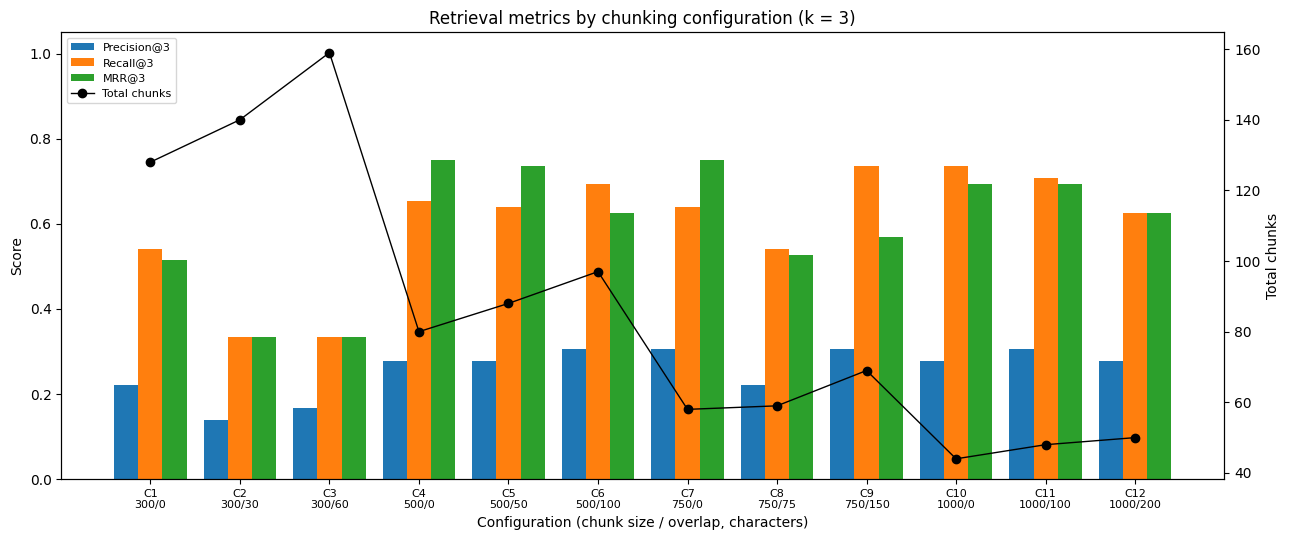

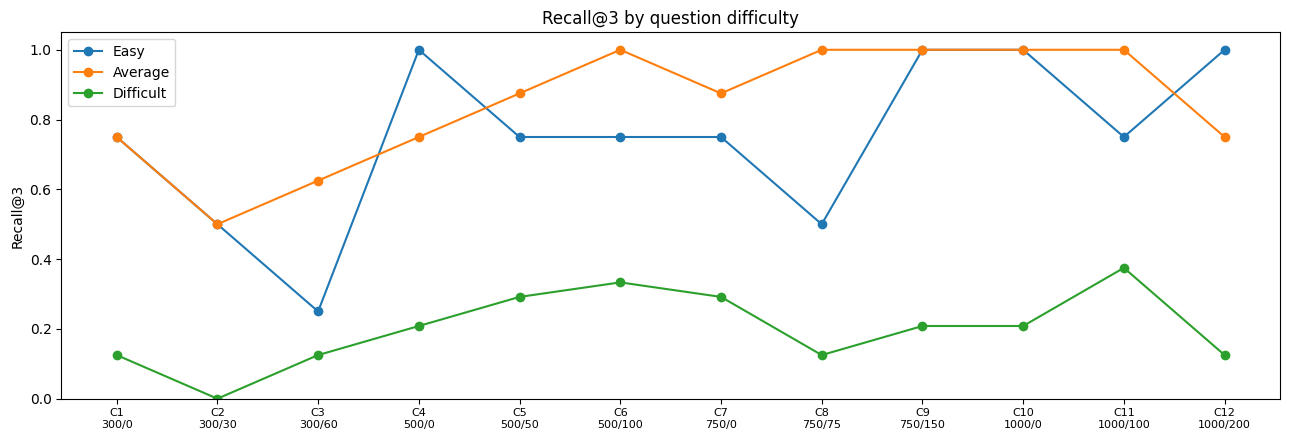

Excel log: pt_f2_outputs/pt_f2_experiment/dmw_source_b_guidance_PT-F2_chunking_experiment.xlsx
Bundle (Excel, CSVs, charts): /content/pt_f2_chunking_results.zip


/content/pt_f2_outputs/pt_f2_experiment/dmw_source_b_guidance_PT-F2_chunking_experiment.xlsx

/content/pt_f2_chunking_results.zip

In [25]:
EXP_EXCEL = EXP_DIR / f"{pdf_path.stem}_PT-F2_chunking_experiment.xlsx"
settings_df = pd.DataFrame([
    ("Source document", Path(pdf_file).name),
    ("Pages with extractable text", len(pages)),
    ("Chunking method", "Character windows per page (create_chunks from PT-F1)"),
    ("Chunk sizes", ", ".join(map(str, CHUNK_SIZES))),
    ("Overlap ratios", ", ".join(f"{int(r * 100)}%" for r in OVERLAP_RATIOS)),
    ("Baseline", f"{baseline_id} = {BASELINE_SIZE} / {BASELINE_OVERLAP}"),
    ("Embedding model", EMBEDDING_MODEL_NAME),
    ("Embedding device", EMBEDDING_DEVICE),
    ("Embedder max input tokens", embedding_model.max_seq_length),
    ("Vector store", "FAISS IndexFlatIP on L2-normalized vectors (exact cosine)"),
    ("Retrieved chunks (k)", EXP_TOP_K),
    ("Test questions", len(GROUND_TRUTH)),
    ("Relevance rule", "Chunk on the unit's page containing all must_contain phrases "
                       "(case/space-insensitive); relevant if it covers >= 1 unit"),
    ("Manual overrides", len(RELEVANCE_OVERRIDES)),
    ("Language model (held constant, not used for metrics)", LLM_NAME),
], columns=["Setting", "Value"])

sheets = {
    "Table_A_Config_Results": table_a,
    "Table_B_By_Difficulty": table_b,
    "Table_C_Retrieval_Log": table_c,
    "Per_Question_Scores": per_question_df,
    "Baseline_Reference": baseline_log,
    "Ground_Truth": ground_truth_df,
    "Settings": settings_df,
}
WIDE_TEXT = {"Chunk_Text": 90, "Question": 45, "Must_Contain": 50, "Expected_Answer": 40,
             "Judgment": 30, "Value": 70, "Setting": 40, "Source_Reference": 30}

with pd.ExcelWriter(EXP_EXCEL, engine="openpyxl") as writer:
    for sheet_name, frame in sheets.items():
        frame.to_excel(writer, sheet_name=sheet_name, index=False)
        ws = writer.sheets[sheet_name]
        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill(fill_type="solid", fgColor="1F4E78")
            cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        for col_idx, col_name in enumerate(frame.columns, start=1):
            letter = ws.cell(row=1, column=col_idx).column_letter
            wrap = col_name in WIDE_TEXT
            ws.column_dimensions[letter].width = WIDE_TEXT.get(col_name, max(12, min(24, len(col_name) + 4)))
            for row in ws.iter_rows(min_row=2, min_col=col_idx, max_col=col_idx):
                row[0].alignment = Alignment(vertical="top", wrap_text=wrap)
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        ws.row_dimensions[1].height = 32

for sheet_name, frame in sheets.items():
    frame.to_csv(EXP_DIR / f"{sheet_name}.csv", index=False, encoding="utf-8-sig")

# Chart 1: the three retrieval metrics per configuration (required for the report).
labels = [f"{r.Configuration}\n{r.Chunk_Size}/{r.Overlap}" for r in table_a.itertuples()]
x = np.arange(len(table_a))
width = 0.27
fig, ax = plt.subplots(figsize=(13, 5.5))
for offset, metric in zip((-width, 0, width), ("Precision@3", "Recall@3", "MRR@3")):
    ax.bar(x + offset, table_a[metric], width, label=metric)
ax2 = ax.twinx()
ax2.plot(x, table_a["Total_Chunks"], color="black", marker="o", linewidth=1, label="Total chunks")
ax2.set_ylabel("Total chunks")
ax.set_xticks(x, labels, fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_xlabel("Configuration (chunk size / overlap, characters)")
ax.set_title("Retrieval metrics by chunking configuration (k = 3)")
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(handles, ["Precision@3", "Recall@3", "MRR@3", "Total chunks"], loc="upper left", fontsize=8)
fig.tight_layout()
CHART_METRICS = EXP_DIR / "fig_metrics_by_configuration.png"
fig.savefig(CHART_METRICS, dpi=200)
plt.show()

# Chart 2: Recall@3 by difficulty level.
pivot_recall = table_b.pivot(index="Configuration", columns="Difficulty", values="Recall@3")
pivot_recall = pivot_recall.reindex(index=config_order, columns=DIFFICULTY_ORDER)
fig, ax = plt.subplots(figsize=(13, 4.5))
for level in DIFFICULTY_ORDER:
    ax.plot(labels, pivot_recall[level], marker="o", label=level)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Recall@3")
ax.set_title("Recall@3 by question difficulty")
ax.tick_params(axis="x", labelsize=8)
ax.legend()
fig.tight_layout()
CHART_DIFFICULTY = EXP_DIR / "fig_recall_by_difficulty.png"
fig.savefig(CHART_DIFFICULTY, dpi=200)
plt.show()

EXP_ARCHIVE = shutil.make_archive("pt_f2_chunking_results", "zip", root_dir=str(EXP_DIR))
print("Excel log:", EXP_EXCEL)
print("Bundle (Excel, CSVs, charts):", EXP_ARCHIVE)
display(FileLink(str(EXP_EXCEL)))
display(FileLink(Path(EXP_ARCHIVE).name))


In [26]:
DOWNLOAD_RESULTS = True  # set True in Colab to download the ZIP
if DOWNLOAD_RESULTS and IN_COLAB:
    colab_files.download(EXP_ARCHIVE)
elif DOWNLOAD_RESULTS:
    display(FileLink(Path(EXP_ARCHIVE).name))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 11: Analysis aids for handout Steps 7 and 8

Prints the numbers needed for each Step 7 question; ties are listed, not hidden. The shortlist applies the Step 8 rule: configurations whose Recall@3 and MRR@3 are within `TOLERANCE` of the best are treated as comparable, then sorted by efficiency. The final recommendation and its justification are yours to write; check the shortlist against Table B and the retrieval log before deciding.

In [27]:
TOLERANCE = 0.05   # "comparable" margin; state it in your report


def best_of(metric):
    top = table_a[metric].max()
    winners = table_a.loc[np.isclose(table_a[metric], top), "Configuration"].tolist()
    return top, winners


print("Q1-Q3: best configuration per metric")
for metric in ("Precision@3", "Recall@3", "MRR@3"):
    top, winners = best_of(metric)
    print(f"  {metric:<12} {top:.4f}  -> {', '.join(winners)}")

print("\nQ4: rank of every configuration on each metric (1 = best, ties share a rank)")
ranks = table_a[["Configuration"]].copy()
for metric in ("Precision@3", "Recall@3", "MRR@3"):
    ranks[metric + "_rank"] = table_a[metric].rank(ascending=False, method="min").astype(int)
print(ranks.to_string(index=False))

print("\nQ5: each metric by chunk size (rows) and overlap % (columns)")
for metric in ("Precision@3", "Recall@3", "MRR@3"):
    print(f"\n{metric}")
    print(table_a.pivot(index="Chunk_Size", columns="Overlap_Pct", values=metric).round(4).to_string())

print("\nQ6: effect of overlap on chunk count (rows = chunk size, columns = overlap %)")
print(table_a.pivot(index="Chunk_Size", columns="Overlap_Pct", values="Total_Chunks").to_string())

print("\nQ7: Difficult questions, sorted by Recall@3 then MRR@3")
print(table_b[table_b["Difficulty"] == "Difficult"]
      .sort_values(["Recall@3", "MRR@3"], ascending=False).to_string(index=False))

print("\nQ8-Q9: evidence units that cannot fit in one chunk of a given size (Min_Span_Chars > size)")
for size in CHUNK_SIZES:
    too_long = ground_truth_df.loc[ground_truth_df["Min_Span_Chars"] > size, "Evidence_Unit"].tolist()
    print(f"  size {size:>4}: {', '.join(too_long) if too_long else 'none'}")
print("  Embedder truncation (% of chunks over the model's token limit):")
print(table_a[["Configuration", "Chunk_Size", "Pct_Chunks_Over_Embedder_Limit"]].to_string(index=False))

print(f"\nQ10: pairs within {TOLERANCE} on all three metrics but with >= 1.5x difference in chunks")
pairs = []
for a, b in itertools.combinations(table_a.to_dict("records"), 2):
    close = all(abs(a[m] - b[m]) <= TOLERANCE for m in ("Precision@3", "Recall@3", "MRR@3"))
    ratio = max(a["Total_Chunks"], b["Total_Chunks"]) / min(a["Total_Chunks"], b["Total_Chunks"])
    if close and ratio >= 1.5:
        pairs.append((a["Configuration"], b["Configuration"], a["Total_Chunks"], b["Total_Chunks"]))
print("\n".join(f"  {p[0]} ({p[2]} chunks) vs {p[1]} ({p[3]} chunks)" for p in pairs) or "  none")

print(f"\nStep 8 shortlist: Recall@3 and MRR@3 within {TOLERANCE} of best, most efficient first")
shortlist = table_a[(table_a["Recall@3"] >= table_a["Recall@3"].max() - TOLERANCE) &
                    (table_a["MRR@3"] >= table_a["MRR@3"].max() - TOLERANCE)]
print(shortlist.sort_values(["Total_Chunks", "Index_Size_KB"])[
    ["Configuration", "Chunk_Size", "Overlap", "Total_Chunks", "Precision@3", "Recall@3", "MRR@3",
     "Questions_Full_Recall", "Questions_No_Relevant", "Embedding_Time_s"]].to_string(index=False))
if len(shortlist) == len(table_a):
    print("All configurations are comparable at this tolerance: the experiment shows no clear winner.")


Q1-Q3: best configuration per metric
  Precision@3  0.3056  -> C6, C7, C9, C11
  Recall@3     0.7361  -> C9, C10
  MRR@3        0.7500  -> C4, C7

Q4: rank of every configuration on each metric (1 = best, ties share a rank)
Configuration  Precision@3_rank  Recall@3_rank  MRR@3_rank
           C1                 9              9          10
           C2                12             11          11
           C3                11             11          11
           C4                 5              5           1
           C5                 5              6           3
           C6                 1              4           6
           C7                 1              6           1
           C8                 9              9           9
           C9                 1              1           8
          C10                 5              1           4
          C11                 1              3           4
          C12                 5              8           6

Q5: each

## Notes and troubleshooting

- **Validation error in Step 7:** fill in `TEST_QUESTIONS` and fix the listed items; use `find_in_pdf()` to copy exact wording.
- **A relevant chunk was judged "No":** the PDF text may break a phrase oddly (hyphenation, line breaks). Shorten the phrase, or add a `RELEVANCE_OVERRIDES` entry with a note.
- **Changing configurations or questions:** rerun from Step 5 onward; every configuration always gets a newly built index.
- **No extractable text:** the PDF needs OCR first.
- **Reproducibility:** the Settings sheet records the document, configurations, embedding model, k and relevance rule. FAISS `IndexFlatIP` is exact search, so results are deterministic for the same inputs.